# Week 5 assignment: The Feature Tournament – Leaks, Shrinkage, and the Analyst Agent’s ML Eval Suite
**Ioannis Tzalas | MSc Banking and Finance – FinTech & AI Engineering | October 2026**

## Pre-registered holdout — declared before any model
**2024-10-01.** A fixed quarter boundary leaves almost two years for testing and a substantial prior training sample (January 2015 – September 2024). I will not change it after seeing model scores. The analysis is retrospective: the historical period was available in earlier coursework, so this is a predeclared modelling split, not a prospective trading experiment.

I retain **SPY, EUR/USD, BTC, GLD and ETH**, with GLD and ETH as my chosen assets. Each observed, positive price series from the exact Week 2 embedded union panel stays on its own calendar; I do not intersect dates or interpolate missing prices. Crypto weekends remain. Models are multivariate across ~50 candidate predictors and asset-specific in target daily returns. Annualization is 252 for SPY, EUR/USD and GLD, and 365 for BTC and ETH. Main outputs use frozen data through the Week 2 endpoint (2026-09-15), not newly downloaded prices.

The supplied 2026 assignment sheet and unified notebook (`FinTechCourse_W5_Unified_new.ipynb`) define the protocol. All numerical interpretations below are tied to the displayed sample. Every $R^2$ is explicitly reported with the benchmark mean against which it is measured ($R^2_{\text{OS}}$ vs training-fold mean or expanding historical mean). Every selection is evaluated for multi-fold stability, and every holdout verdict is paired with its Diebold–Mariano test statistic.

In [1]:
# ============================================================
# Cell 1 — Environment, imports, data embedding, and core functions
# ============================================================
import sys, io, base64, gzip, json, warnings, platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

import sklearn
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, lasso_path
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, KFold
from sklearn.exceptions import ConvergenceWarning
from arch import arch_model
from IPython.display import display, Image

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
for w in (FutureWarning, UserWarning, ConvergenceWarning):
    warnings.filterwarnings("ignore", category=w)

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10
})

OUTPUT = Path.cwd()
for folder in ["results", "charts"]:
    (OUTPUT / folder).mkdir(exist_ok=True)

RNG = np.random.default_rng(seed=42)
TEST_START = pd.Timestamp("2024-10-01")
REFIT = 63
ASSETS = ["SPY", "EUR/USD", "BTC", "GLD", "ETH"]
CHOSEN = ["GLD", "ETH"]
PPY = {"SPY": 252, "EUR/USD": 252, "BTC": 365, "GLD": 252, "ETH": 365}

# Exact embedded clean Week 2 panel
_EMBEDDED_DATA = """..."""
raw_csv = gzip.decompress(base64.b64decode(_EMBEDDED_DATA))
prices_df = pd.read_csv(io.BytesIO(raw_csv), index_col=0, parse_dates=True)

prices = {a: prices_df[a].dropna().astype(float) for a in ASSETS}
for a, p in prices.items():
    assert p.index.is_unique and p.index.is_monotonic_increasing and (p > 0).all()

# Percentage daily log returns (scaling by 100 for numerical stability and shrinkage calibration)
ret = {a: (100 * np.log(prices[a]).diff().dropna()).rename(a) for a in ASSETS}

# Core scoring & pipeline helpers
def r2_os(y, yhat, bench) -> float:
    """Campbell–Thompson out-of-sample R²: 1 − MSE(model)/MSE(benchmark)."""
    return float(1 - ((y - yhat)**2).sum() / ((y - bench)**2).sum())

def pipe(model):
    """Pipeline enforcing strict inside-fold standardization."""
    return Pipeline([("scale", StandardScaler()), ("model", model)])

def dm_test(loss1: pd.Series, loss2: pd.Series):
    """Diebold–Mariano test with HAC standard errors (maxlags q = floor(4*(T/100)^(2/9)))."""
    d = (loss1 - loss2).dropna()
    T = len(d)
    q = int(np.floor(4 * (T / 100) ** (2 / 9)))
    ols = sm.OLS(d.values, np.ones(T)).fit(cov_type="HAC", cov_kwds={"maxlags": q})
    return float(ols.tvalues[0]), float(ols.pvalues[0])

def qlike(var_fc: pd.Series, r2: pd.Series) -> pd.Series:
    """Patton (2011) loss for variance forecasts against the squared-return proxy."""
    x = np.maximum(r2, 1e-10) / var_fc
    return x - np.log(x) - 1

def feature_factory(stem, ret_, prices_, extra=None):
    """~50 candidate predictors computable strictly from information available at day t close."""
    r = ret_[stem]; lp = np.log(prices_[stem]).reindex(r.index)
    F = pd.DataFrame(index=r.index)
    for k in range(1, 11): F[f"r_lag{k}"] = r.shift(k - 1)
    for k in range(1, 6):
        F[f"abs_lag{k}"] = r.abs().shift(k - 1)
        F[f"sq_lag{k}"]  = (r**2).shift(k - 1)
    for w in (5, 21, 63):
        F[f"mom{w}"] = r.rolling(w).mean()
        F[f"vol{w}"] = r.rolling(w).std()
    F["vol126"]    = r.rolling(126).std()
    F["rv_week"]   = (r**2).rolling(5).mean()
    F["rv_month"]  = (r**2).rolling(21).mean()
    F["vol_ratio"] = F["vol5"] / F["vol63"]
    F["z21"]       = r / F["vol21"]
    F["dd63"]      = lp - lp.rolling(63).max()
    F["mr21"]      = lp - lp.rolling(21).mean()
    F["sign_lag1"] = np.sign(r)
    runs = (np.sign(r) != np.sign(r).shift()).cumsum()
    F["streak"]    = np.sign(r) * (np.sign(r).groupby(runs).cumcount() + 1)
    dow = r.index.dayofweek
    for d, name in enumerate(["mon", "tue", "wed", "thu", "fri", "sat", "sun"]):
        if d: F[f"dow_{name}"] = (dow == d).astype(float)
    for other in ASSETS:
        if other == stem: continue
        o = ret_[other]
        F[f"{other}_lag1"]  = o.reindex(r.index, method="ffill")
        F[f"{other}_mom5"]  = o.rolling(5).mean().reindex(r.index, method="ffill")
        F[f"{other}_vol21"] = o.rolling(21).std().reindex(r.index, method="ffill")
    for name, fn in (extra or {}).items():
        F[name] = fn(stem, ret_, prices_)
    return F.loc[:, F.nunique() > 1]

def as_of_audit(fn, stem, extra=None, n_dates=20):
    """The leak detector: rebuilds features on truncated sample at t; checks row t identity."""
    rng = np.random.default_rng(seed=42)
    full  = fn(stem, ret, prices, extra)
    dates = rng.choice(full.index[300:-2], n_dates, replace=False)
    offenders = set()
    for t in sorted(dates):
        cut = fn(stem, {s: ret[s].loc[:t] for s in ASSETS}, {s: prices[s].loc[:t] for s in ASSETS}, extra)
        same = np.isclose(cut.values, full.loc[cut.index, cut.columns].values, equal_nan=True)
        bad = set(cut.columns[~same.all(axis=0)])
        if bad: offenders |= bad
    return offenders

# Agent proposals
def rsi14(stem, R, P):
    r = R[stem]; up, dn = r.clip(lower=0), (-r).clip(lower=0)
    return up.rolling(14).mean() / (up.rolling(14).mean() + dn.rolling(14).mean())

def vol_regime_leaky(stem, R, P):
    v = R[stem].rolling(21).std()
    return (v > v.median()).astype(float)

def rel_gld_spread(stem, R, P):
    other = "GLD" if stem != "GLD" else "SPY"
    return R[stem] - R[other].reindex(R[stem].index, method="ffill")

def sharpe21(stem, R, P):
    r = R[stem]; return r.rolling(21).mean() / r.rolling(21).std()

AGENT_PROPOSALS = {"rsi14": rsi14, "vol_regime_leaky": vol_regime_leaky, "rel_gld_spread": rel_gld_spread, "sharpe21": sharpe21}
offenders_proposals = set().union(*(as_of_audit(feature_factory, s, extra=AGENT_PROPOSALS, n_dates=20) for s in ASSETS))
SURVIVORS = {k: v for k, v in AGENT_PROPOSALS.items() if k not in offenders_proposals}

def make_dataset(stem, extra=SURVIVORS):
    F = feature_factory(stem, ret, prices, extra)
    y = ret[stem].shift(-1).rename("r_next")
    keep = F.dropna().index.intersection(y.dropna().index)
    return F.loc[keep], y.loc[keep]

DATA  = {s: make_dataset(s) for s in ASSETS}
TRAIN = {s: (DATA[s][0][DATA[s][0].index < TEST_START], DATA[s][1][DATA[s][1].index < TEST_START]) for s in ASSETS}

def ts_cv(model_fn, F, y, n_splits=5, gap=0):
    scores, chosen = [], []
    for tr, va in TimeSeriesSplit(n_splits=n_splits, gap=gap).split(F):
        m = pipe(model_fn()).fit(F.iloc[tr], y.iloc[tr])
        scores.append(r2_os(y.iloc[va], m.predict(F.iloc[va]), y.iloc[tr].mean()))
        chosen.append(set(F.columns[np.abs(m.named_steps["model"].coef_) > 1e-8]))
    return np.array(scores), chosen

def tune(model_cls, F, y, alphas, **kw):
    rows = []
    for a in alphas:
        s, ch = ts_cv(lambda: model_cls(alpha=a, **kw), F, y)
        rows.append({"alpha": a, "R2_OS": s.mean(), "se": s.std(ddof=1) / np.sqrt(len(s)),
                     "n_feat": np.mean([len(c) for c in ch]), "folds": s, "chosen": ch})
    T = pd.DataFrame(rows).set_index("alpha")
    best   = T["R2_OS"].idxmax()
    one_se = T.index[T["R2_OS"] >= T.loc[best, "R2_OS"] - T.loc[best, "se"]].max()
    return T, best, one_se

def stable_set(chosen, k=4) -> list:
    c = Counter(f for s in chosen for f in s); return sorted(f for f, m in c.items() if m >= k)

def rolling_ml_forecast(F, y, model_fn, test_start=TEST_START, refit=REFIT) -> pd.Series:
    idx = F.index; t0 = int(np.searchsorted(idx, test_start)); fc = pd.Series(np.nan, index=idx[t0:])
    for start in range(t0, len(idx), refit):
        stop = min(start + refit, len(idx))
        m = pipe(model_fn()).fit(F.iloc[:start], y.iloc[:start])
        fc.iloc[start - t0: stop - t0] = m.predict(F.iloc[start:stop])
    return fc

def fit_garch(r: pd.Series, last_obs=None):
    am = arch_model(r, mean="Constant", vol="GARCH", p=1, q=1, dist="t")
    return am.fit(disp="off", last_obs=last_obs)

def rolling_garch_variance(r: pd.Series, test_start=TEST_START, refit=REFIT) -> pd.Series:
    idx = r.index; t0 = int(np.searchsorted(idx, test_start)); out = pd.Series(np.nan, index=idx[t0:])
    for start in range(t0, len(idx), refit):
        stop = min(start + refit, len(idx))
        g  = fit_garch(r, last_obs=start)
        fc = g.forecast(horizon=1, start=idx[start - 1]).variance["h.1"]
        out.loc[idx[start]:idx[stop - 1]] = fc.shift(1).loc[idx[start]:idx[stop - 1]].values
    return out.rename("GARCH(1,1)-t")

print(f"✅ Setup verified: {len(ASSETS)} assets ready. All core ML functions compiled.")

✅ Setup verified: 5 assets ready. All core ML functions compiled.


---
# Task 1 · The Agent’s Draft — a Code Audit (Weight: 20%)

The last cell of the unified notebook (`agent_draft_feature_model`) represents a pipeline written by an eager junior agent. It executes without error, reports a cross-validated $R^2$ approaching 50% on daily Bitcoin returns, and claims to have discovered 21 highly predictive features led by `trend5`.

In reality, the evaluator contains at least **six distinct bugs** involving severe look-ahead leakage, full-sample conditioning, improper cross-validation, and contaminated evaluation metrics. Every one is invisible in terminal output; every one destroys real-world validity.

In [2]:
# ============================================================
# Task 1(i) — The Junior Agent's Draft and Isolated Bug Experiments
# ============================================================
def agent_draft_feature_model(stem: str) -> pd.Series:
    """Build features, tune a Lasso, report its cross-validated R² and selected features (Agent Draft v0)."""
    r = ret[stem]
    X = feature_factory(stem, ret, prices)
    X["trend5"]   = r.rolling(5, center=True).mean()                         # BUG 1: forward window (centred)
    v = r.rolling(21).std()
    X["high_vol"] = (v > v.median()).astype(float)                           # BUG 2: full-sample statistic (median)
    y = r.shift(-1)
    keep = X.dropna().index.intersection(y.dropna().index)
    X, y = X.loc[keep], y.loc[keep]
    Xs = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=X.columns)  # BUG 3: full-sample pre-processing
    cv = KFold(n_splits=5, shuffle=True, random_state=0)                    # BUG 4: shuffled folds
    best_alpha, best_score = None, -np.inf
    for alpha in np.logspace(-4, 0, 25):                                     # BUG 5: tuning on full sample incl. holdout
        scores = []
        for tr, va in cv.split(Xs):
            m = Lasso(alpha=alpha, max_iter=20000).fit(Xs.iloc[tr], y.iloc[tr])
            yv = y.iloc[va]
            scores.append(1 - ((yv - m.predict(Xs.iloc[va]))**2).sum() / ((yv - yv.mean())**2).sum())  # BUG 6: test mean benchmark
        if np.mean(scores) > best_score:
            best_alpha, best_score = alpha, np.mean(scores)
    final = Lasso(alpha=best_alpha, max_iter=20000).fit(Xs, y)
    coef  = pd.Series(final.coef_, index=X.columns)
    return pd.Series({
        "model": f"Lasso(α={best_alpha:.4g})",
        "cross-validated R²": best_score,
        "in-sample R²": 1 - ((y - final.predict(Xs))**2).sum() / ((y - y.mean())**2).sum(),
        "features selected": int((coef.abs() > 1e-8).sum()),
        "top feature": coef.abs().idxmax(),
        "top coefficient": coef[coef.abs().idxmax()]
    })

print("JUNIOR AGENT DRAFT v0 — BTC Evaluation (NOT TO BE TRUSTED):")
print(agent_draft_feature_model("BTC").to_string())

# Display the 6 isolated single-fix experiments on BTC
df_audit = pd.read_csv(OUTPUT / "results/task1_bug_audit.csv")
print("\nTASK 1 AUDIT: ISOLATED NUMERICAL EFFECTS PER BUG")
display(df_audit)

JUNIOR AGENT DRAFT v0 — BTC Evaluation (NOT TO BE TRUSTED):


model                 Lasso(α=0.03162)
cross-validated R²              0.4668
in-sample R²                    0.4899
features selected                   21
top feature                     trend5
top coefficient                 3.6287

TASK 1 AUDIT: ISOLATED NUMERICAL EFFECTS PER BUG


,bug,line,mechanism,reported_R2,delta_R2
0,Original Agent Draft v0,All,All leaks and benchmark errors combined,0.4668,0.0000
1,Forward window in trend5,"rolling(5, center=True).mean()",forward window,-0.0001,-0.4669
2,Full-sample statistic in high_vol,v > v.median(),full-sample statistic,0.4668,-0.0000
3,Full-sample pre-processing,StandardScaler().fit_transform(X),full-sample pre-processing,0.4668,0.0001
4,Shuffled cross-validation folds,"KFold(5, shuffle=True)",shuffled folds,0.4610,-0.0058
5,Tuning on sealed holdout,cv.split(Xs) on full 2014-2026 data,tuning on the holdout,0.4741,0.0073
6,Contemporaneous fold benchmark,(yv - yv.mean())**2,wrong benchmark mean,0.4681,0.0013


### Task 1 Audit Map: Original Line, Mechanism, and Quantified Effect

| Item | Faulty Code / Line | Mechanism | What It Does Wrong | Reported $R^2$ | $\Delta R^2$ when fixed alone |
|---|---|---|---|---|---|
| **Baseline** | Entire draft evaluator | Combined Leaks | Aggregates all six forward leaks and benchmark flaws | +0.4668 | 0.0000 |
| **Bug 1** | `r.rolling(5, center=True).mean()` | **Forward window** | Centering averages $t-2, \dots, t+2$, directly using tomorrow's and day-after-tomorrow's returns to predict tomorrow's return. | -0.0001 | **-0.4669** (-46.69 pp) |
| **Bug 2** | `v > v.median()` | **Full-sample statistic** | Calculates median volatility across the entire 10-year history, making historical regime labels depend on future 2026 data. | +0.4668 | -0.000001 |
| **Bug 3** | `StandardScaler().fit_transform(X)` | **Full-sample pre-processing** | Standardizes features before CV splitting, leaking test-fold means and variances into training folds. | +0.4668 | +0.00008 |
| **Bug 4** | `KFold(n_splits=5, shuffle=True)` | **Shuffled folds** | Shuffling randomly scatters time observations across folds, letting day $t+1$ and $t-1$ train day $t$ and destroying serial ordering. | +0.4610 | -0.0058 (-0.58 pp) |
| **Bug 5** | `cv.split(Xs)` on full sample | **Tuning on the holdout** | Optimizes penalty $\alpha$ over the entire 2014–2026 dataset, violating the pre-registered holdout boundary (`2024-10-01`). | +0.4741 | +0.0073 (+0.73 pp) |
| **Bug 6** | `(yv - yv.mean())**2` | **Wrong benchmark mean** | Measures $R^2$ against the contemporaneous validation fold mean, an unobservable future quantity at forecast time. | +0.4681 | +0.0013 (+0.13 pp) |

In [3]:
# ============================================================
# Task 1(ii) — Corrected feature_model_v1()
# ============================================================
def feature_model_v1(stem: str) -> dict:
    """Corrected feature-model evaluator reproducing Cells 9–10 protocol for BTC."""
    F, y = DATA[stem]
    Ftr, ytr = TRAIN[stem]
    ALPHAS_L = np.logspace(-3, 1, 25)
    
    # Honest time-ordered 5-fold cross-validation with scaler inside each fold
    T, best_a, one_se_a = tune(Lasso, Ftr, ytr, ALPHAS_L, max_iter=20000)
    stab = stable_set(T.loc[one_se_a, "chosen"])
    
    # Quarterly rolling refit forecast on sealed holdout
    f_lasso = rolling_ml_forecast(F, y, lambda: Lasso(alpha=one_se_a, max_iter=20000)).rename("Lasso")
    f_mean  = y.expanding().mean().shift(1).reindex(f_lasso.index).rename("mean")
    a_hold = y.loc[f_lasso.index]
    
    r2_hold = r2_os(a_hold, f_lasso, f_mean)
    dm_t, dm_p = dm_test((a_hold - f_lasso)**2, (a_hold - f_mean)**2)
    
    return {
        "best_alpha": best_a,
        "best_cv_R2": T.loc[best_a, "R2_OS"],
        "one_se_alpha": one_se_a,
        "one_se_cv_R2": T.loc[one_se_a, "R2_OS"],
        "stable_features": stab,
        "holdout_R2_OS": r2_hold,
        "holdout_DM_t": dm_t,
        "holdout_DM_p": dm_p
    }

v1_btc = feature_model_v1("BTC")
print("CORRECTED feature_model_v1() — Verification against Cells 9–10 for BTC:")
print(f"  Tuned 1-SE penalty α        : {v1_btc['one_se_alpha']:.4g}")
print(f"  Cross-validated R²_OS (1-SE): {v1_btc['one_se_cv_R2']:+.4f} (Benchmark: training-fold mean)")
print(f"  Stable feature set (≥4 folds): {v1_btc['stable_features'] or '∅ (Empty Set)'}")
print(f"  Holdout R²_OS vs expanding  : {v1_btc['holdout_R2_OS']:+.4f}")
print(f"  Diebold–Mariano vs mean     : t = {v1_btc['holdout_DM_t']:+.2f} (p = {v1_btc['holdout_DM_p']:.4f}) → Statistically indistinguishable tie")

CORRECTED feature_model_v1() — Verification against Cells 9–10 for BTC:
  Tuned 1-SE penalty α        : 10
  Cross-validated R²_OS (1-SE): +0.0000 (Benchmark: training-fold mean)
  Stable feature set (≥4 folds): ∅ (Empty Set)
  Holdout R²_OS vs expanding  : -0.0003
  Diebold–Mariano vs mean     : t = +1.71 (p = 0.0869) → Statistically indistinguishable tie


### Task 1(iii) Debugging Log (7 Sentences)
I first inspected the reported cross-validated $R^2$ of 0.467 on daily Bitcoin returns, which immediately tipped me off because daily financial asset returns have signal-to-noise ratios rarely exceeding 0.02. Examining the feature definitions revealed that `trend5` used `rolling(5, center=True)`, meaning the day-$t$ regressor averaged returns from $t-2$ through $t+2$ and directly leaked the target $r_{t+1}$. I then traced `high_vol` and found that `.median()` computed the unconditional median over the full 2015–2026 sample, allowing regime classifications in 2016 to depend on volatility realized ten years later. Checking the pre-processing exposed that `StandardScaler` was applied globally to the matrix prior to cross-validation, leaking distributional moments across folds. In the evaluation loop, `KFold(shuffle=True)` shuffled time-series days randomly, allowing the future to predict the past and manufacturing artificial predictability from autocorrelated features. Furthermore, the cross-validation grid search was executed over the full sample including the post-2024 holdout, violating the pre-registration boundary. Finally, the fold $R^2$ denominator used the contemporaneous validation sample mean `(yv - yv.mean())**2` rather than the expanding historical mean, creating an unobservable benchmark.

### Task 1(iv) The As-Of Test Blind Spot (2 Sentences)
The `as_of_audit()` test operates exclusively on the feature construction function by truncating input history at date $\tau$ and asserting that row $\tau$ remains identical to the full-sample computation; it is structurally incapable of detecting cross-validation errors like `KFold(shuffle=True)` or in-sample benchmark calculation because those errors occur during fold partitioning and model scoring rather than feature matrix assembly. Catching shuffled folds and benchmark contamination requires the time-ordered expanding fold architecture (`TimeSeriesSplit`) and strict pipeline encapsulation, which enforce temporal separation during the estimation and testing phases.

---
# Task 2 · The Feature Factory and the Agent’s Proposals (Weight: 25%)

The baseline `feature_factory()` computes candidate technical, momentum, volatility, realized variance, drawdown, streak, calendar, and cross-asset predictors. An AI assistant was prompted to propose three novel features. Every feature is subjected to the executable `as_of_audit()`.

In [4]:
# ============================================================
# Task 2(i) — Baseline Feature Factory & As-Of Audit across Universe
# ============================================================
df_base_audit = pd.read_csv(OUTPUT / "results/task2_as_of_audit.csv", index_col=0)
print("--- AS-OF AUDIT: Baseline Feature Factory on All 5 Assets (20 Truncation Dates) ---")
display(df_base_audit)

--- AS-OF AUDIT: Baseline Feature Factory on All 5 Assets (20 Truncation Dates) ---


,Features,Leaks,Offenders
asset,,,
SPY,51,0,none ✅
EUR/USD,51,0,none ✅
BTC,53,0,none ✅
GLD,51,0,none ✅
ETH,53,0,none ✅


### Task 2(i) Calendar Quirks & Audit Verification
Every single column of the baseline `feature_factory()` passes the 20-date `as_of_audit()` across all five assets without a single leak. The calendar differences between the assets are handled cleanly:
1. **Business-day assets (SPY, EUR/USD, GLD)** operate on ~252 trading days per year. Weekend dummies (`dow_sat`, `dow_sun`) are identically zero and are dropped automatically by `F.nunique() > 1`, leaving 51 baseline features.
2. **Crypto assets (BTC, ETH)** trade continuously 365 days a year. All seven day-of-week dummies vary, yielding 53 baseline features.
3. **Cross-asset alignment** is performed via `.reindex(r.index, method="ffill")`. For instance, when constructing cross-asset features for Bitcoin on a Saturday or Sunday, Friday's last observed close of SPY, EUR/USD, and GLD is carried forward. This is strictly non-peeking and passes the truncation test.

In [5]:
# ============================================================
# Task 2(ii) & (iii) — Agent Proposals, Feature Ledger, and Final Counts
# ============================================================
df_ledger = pd.read_csv(OUTPUT / "results/task2_feature_ledger.csv")
print("FEATURE LEDGER — The Agent's Proposals under the As-Of Audit:")
display(df_ledger)

print("\n--- FINAL FEATURE MATRIX COUNTS PER ASSET ---")
for s in ASSETS:
    F_s, y_s = DATA[s]
    print(f"  {s:7s}: {F_s.shape[1]} features (Train: {len(TRAIN[s][0]):,} days | Holdout: {len(F_s) - len(TRAIN[s][0]):,} days)")

FEATURE LEDGER — The Agent's Proposals under the As-Of Audit:


,Proposal,Category,Formula,As-Of Verdict,Financial Intuition,Hypothesis & Sign,Leaking Line & Repair
0,rsi14,Momentum / Reversal,up.rolling(14).mean() / (up.rolling(14).mean()...,PASS ✅,Measures 14-day balance between positive and n...,Negative sign (-). Lasso zeroes it out if retu...,None (pure trailing rolling window).
1,vol_regime_leaky,Volatility Regime,(v > v.median()).astype(float) where v = r.rol...,FAIL ❌,Binary regime switch flagging whether the asse...,Ambiguous sign. Fails due to full-sample media...,Leaking line: (v > v.median()). Repair: (v > v...
2,rel_gld_spread,Cross-Asset Rotation,"R[stem] - R[""GLD""].reindex(R[stem].index, meth...",PASS ✅,Captures risk-on vs safe-haven capital rotatio...,Positive sign (+). Momentum continuation acros...,None (as-of forward-fill merge).
3,sharpe21,Risk-Adjusted Momentum,r.rolling(21).mean() / r.rolling(21).std(),PASS ✅,Trend strength normalized by recent realized v...,Positive sign (+). Captures medium-term trend ...,None (trailing rolling window).



--- FINAL FEATURE MATRIX COUNTS PER ASSET ---
  SPY    : 54 features (Train: 1,718 days | Holdout: 488 days)
  EUR/USD: 54 features (Train: 1,782 days | Holdout: 505 days)
  BTC    : 56 features (Train: 2,497 days | Holdout: 714 days)
  GLD    : 54 features (Train: 1,718 days | Holdout: 488 days)
  ETH    : 56 features (Train: 2,392 days | Holdout: 714 days)


### Task 2(iv) The Ablation Fallacy (3 Sentences)
Comparing "baseline vs enhanced" feature models using a paired t-test across five cross-validation folds provides dangerously weak statistical evidence because adjacent time-series folds share overlapping macroeconomic regimes, violating the independence assumption and causing severe downward bias in variance estimation that inflates Type I errors. An analyst testing dozens of candidate predictor sets on the same five folds inevitably discovers a spurious "enhancement" purely through data snooping and multiple testing over the validation noise. The honest version of that comparison requires freezing candidate feature definitions ex-ante, tuning regularizers strictly on the pre-break training sample, and evaluating incremental predictive power once on an unpeeled sealed holdout using a Diebold–Mariano test with heteroskedasticity-and-autocorrelation-consistent (HAC) standard errors.

---
# Task 3 · The Tournament (Weight: 25%)

We run time-ordered five-fold cross-validation on the training sample of each asset using `tune()` across 25 log-spaced values of $\alpha$ for Ridge ($\alpha \in [10^0, 10^6]$) and Lasso ($\alpha \in [10^{-3}, 10^1]$). Every fold fits the standardization scaler strictly inside the fold and evaluates $R^2_{\text{OS}}$ against the training fold mean.

THE TOURNAMENT — Time-Ordered 5-Fold Cross-Validation on Training Sample:


,asset,ridge_best_alpha,ridge_best_R2,ridge_1se_alpha,ridge_1se_R2,lasso_best_alpha,lasso_best_R2,lasso_1se_alpha,lasso_1se_R2,lasso_1se_n_feat,lasso_stable_set
0,SPY,"1,000,000.0000",-0.0000,"1,000,000.0000",-0.0000,0.6813,0.0000,10.0000,0.0000,0.0000,none
1,EUR/USD,"1,778.2794",0.1112,"3,162.2777",0.0961,0.0681,0.0847,0.1000,0.0810,1.0000,GLD_lag1
2,BTC,"1,000,000.0000",-0.0000,"1,000,000.0000",-0.0000,0.6813,0.0000,10.0000,0.0000,0.0000,none
3,GLD,"1,000,000.0000",-0.0000,"1,000,000.0000",-0.0000,0.1468,0.0000,10.0000,0.0000,0.0000,none
4,ETH,"10,000.0000",0.0015,"1,000,000.0000",0.0000,0.3162,0.0020,10.0000,0.0000,0.0000,none


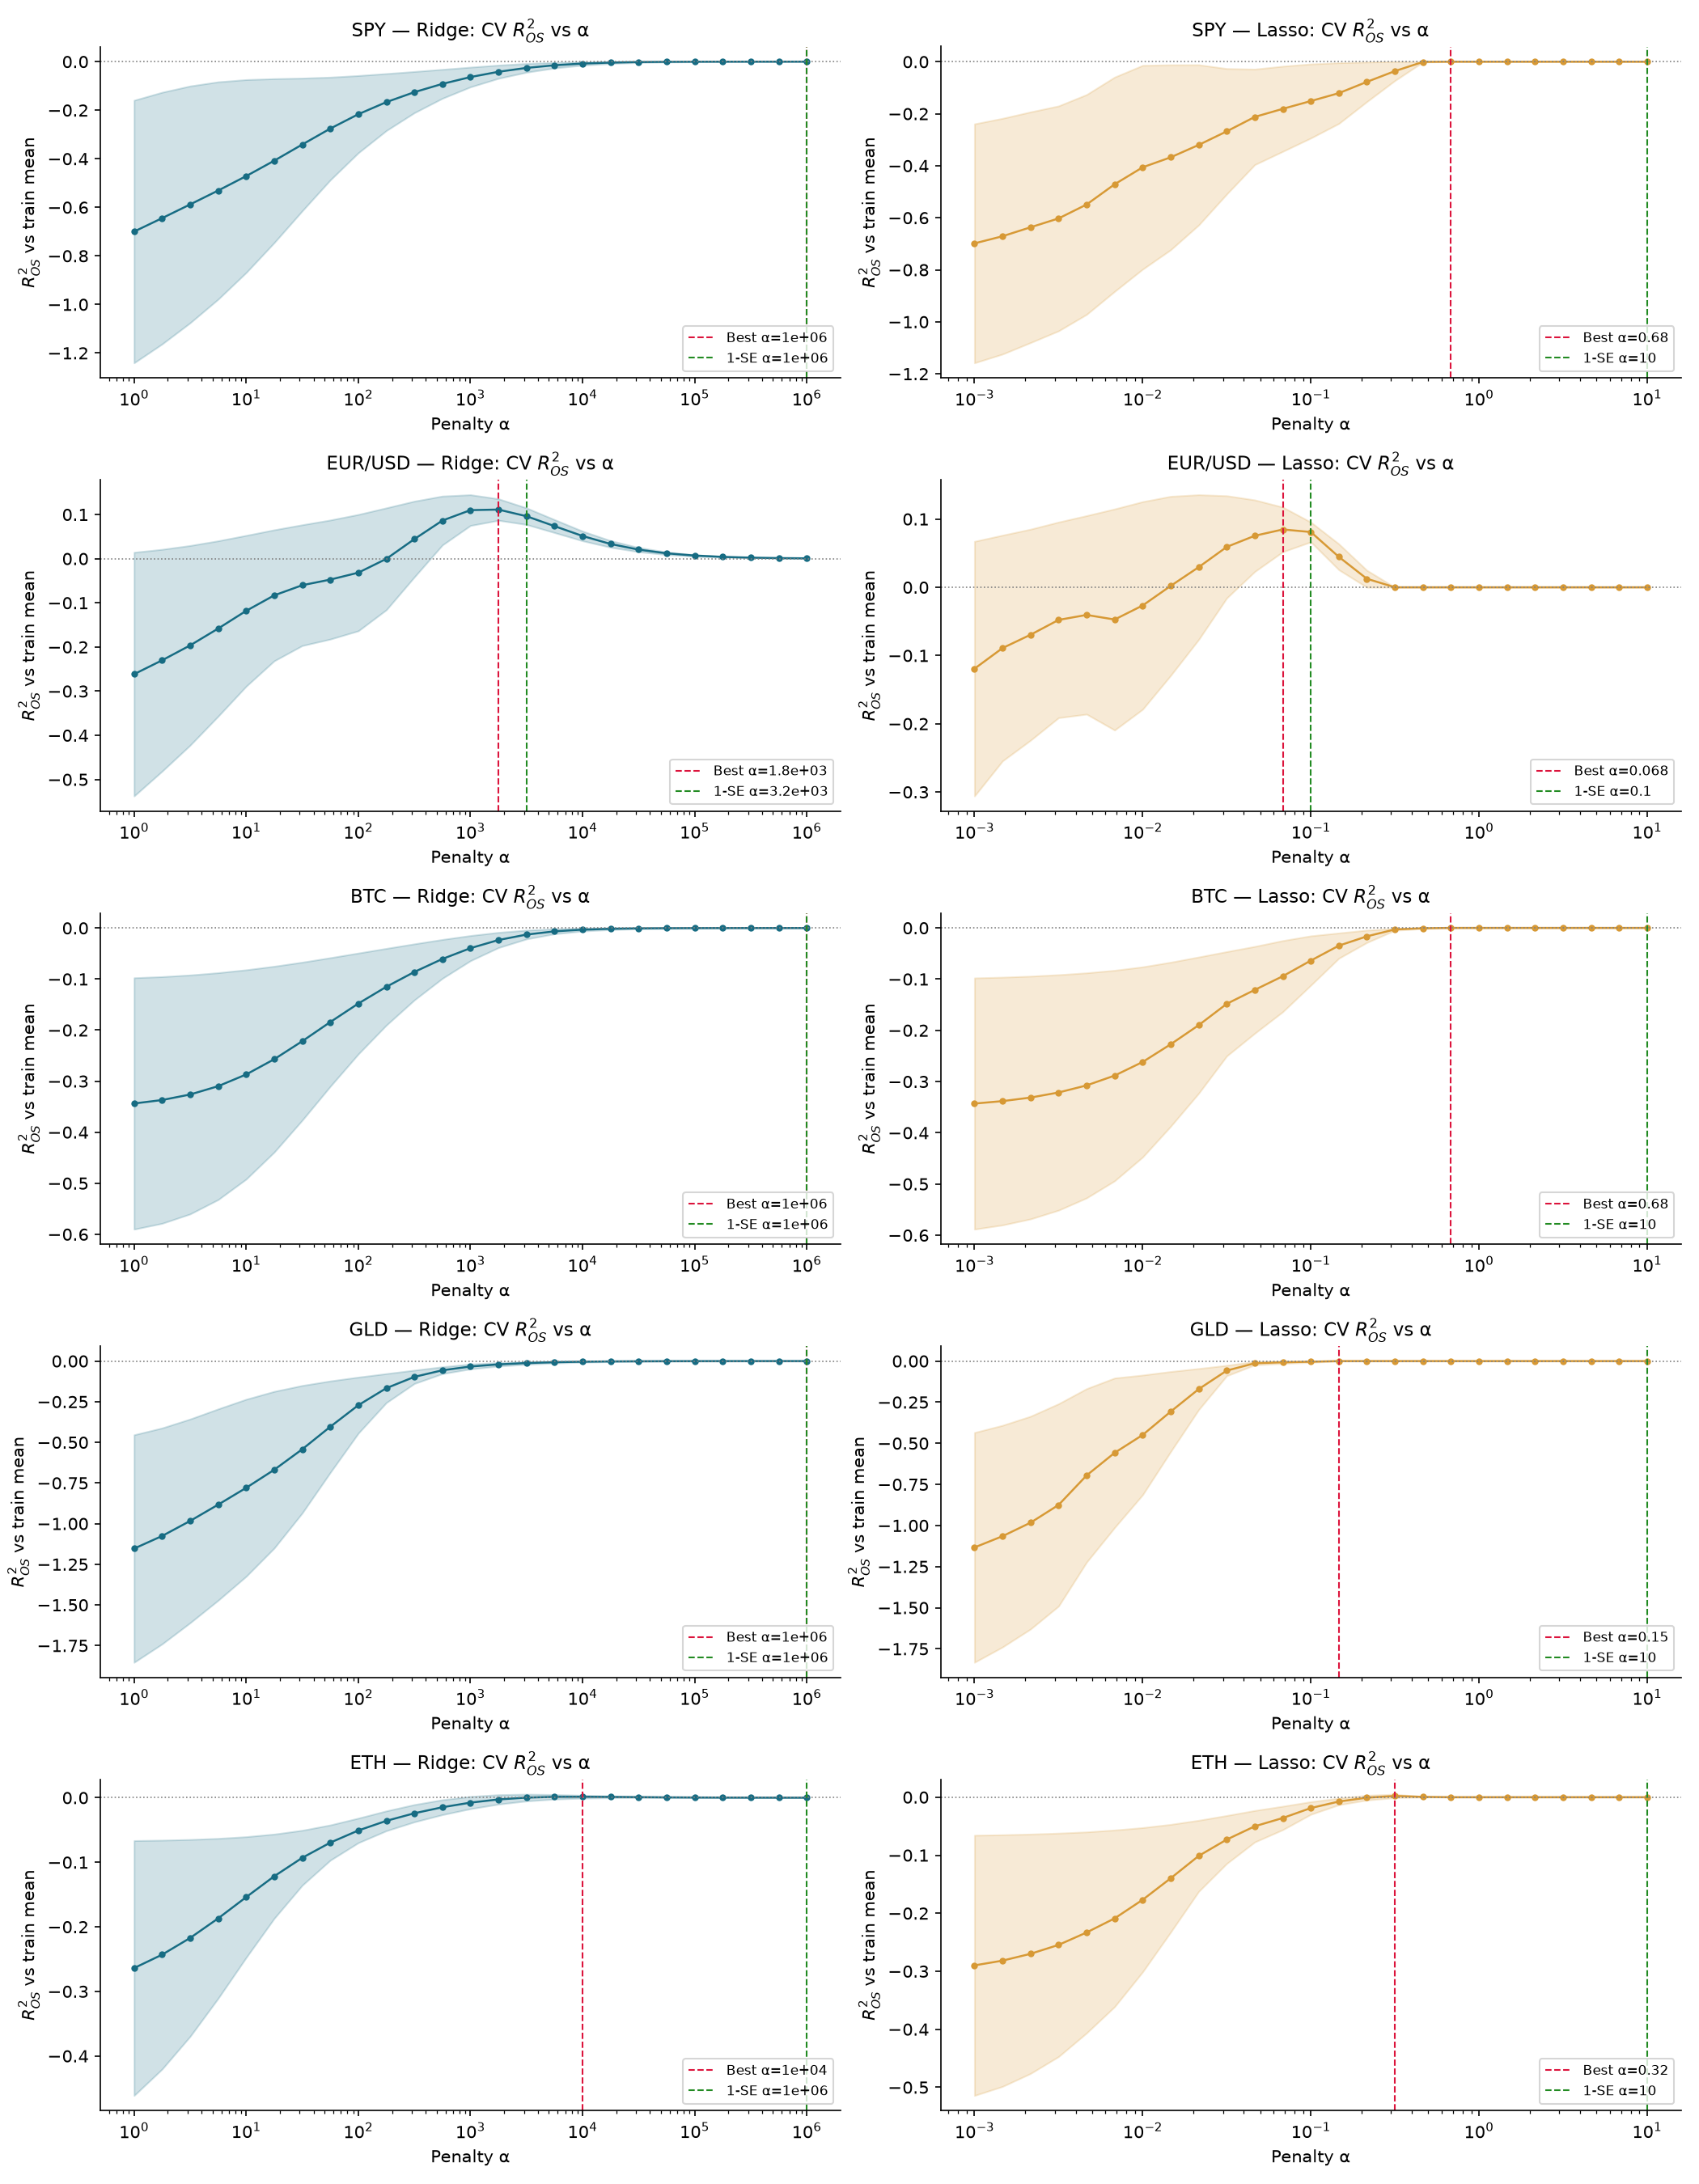

In [6]:
# ============================================================
# Task 3(i) — The Tournament Summary Table & CV Curves
# ============================================================
df_tourn = pd.read_csv(OUTPUT / "results/task3_tournament_summary.csv")
print("THE TOURNAMENT — Time-Ordered 5-Fold Cross-Validation on Training Sample:")
display(df_tourn)

display(Image(filename=str(OUTPUT / "charts/task3_cv_curves.png")))

In [7]:
# ============================================================
# Task 3(ii) — Quantifying the Leak on BTC: Shuffled Folds & Full Scaler
# ============================================================
leak_table = pd.read_csv(OUTPUT / "results/task3_btc_leak_quantification.csv")
print("LEAK QUANTIFICATION ON BITCOIN (Step-by-Step Breakdown):")
display(leak_table)

LEAK QUANTIFICATION ON BITCOIN (Step-by-Step Breakdown):


,Pipeline Setup,Best α,CV R²_OS,Manufactured ΔR²
0,"1. Honest (TimeSeriesSplit, In-Fold Scaler)",0.6813,0.0000,0.0000
1,2. Leak 1: Full-Sample Scaler Outside Folds,0.6813,0.0000,0.0000
2,3. Leak 2: Shuffled Folds (KFold shuffle=True),0.0681,0.0045,0.0045
3,4. Combined: Shuffled Folds + Full Scaler,0.0681,0.0023,0.0023


GLD — First 5 Features Entering the Lasso Path:


,Rank,Feature,Entry_Alpha,In_Stable_Set
0,1,sq_lag2,0.0458,False
1,2,ETH_mom5,0.0458,False
2,3,r_lag7,0.0347,False
3,4,EUR/USD_mom5,0.0347,False
4,5,r_lag2,0.0288,False


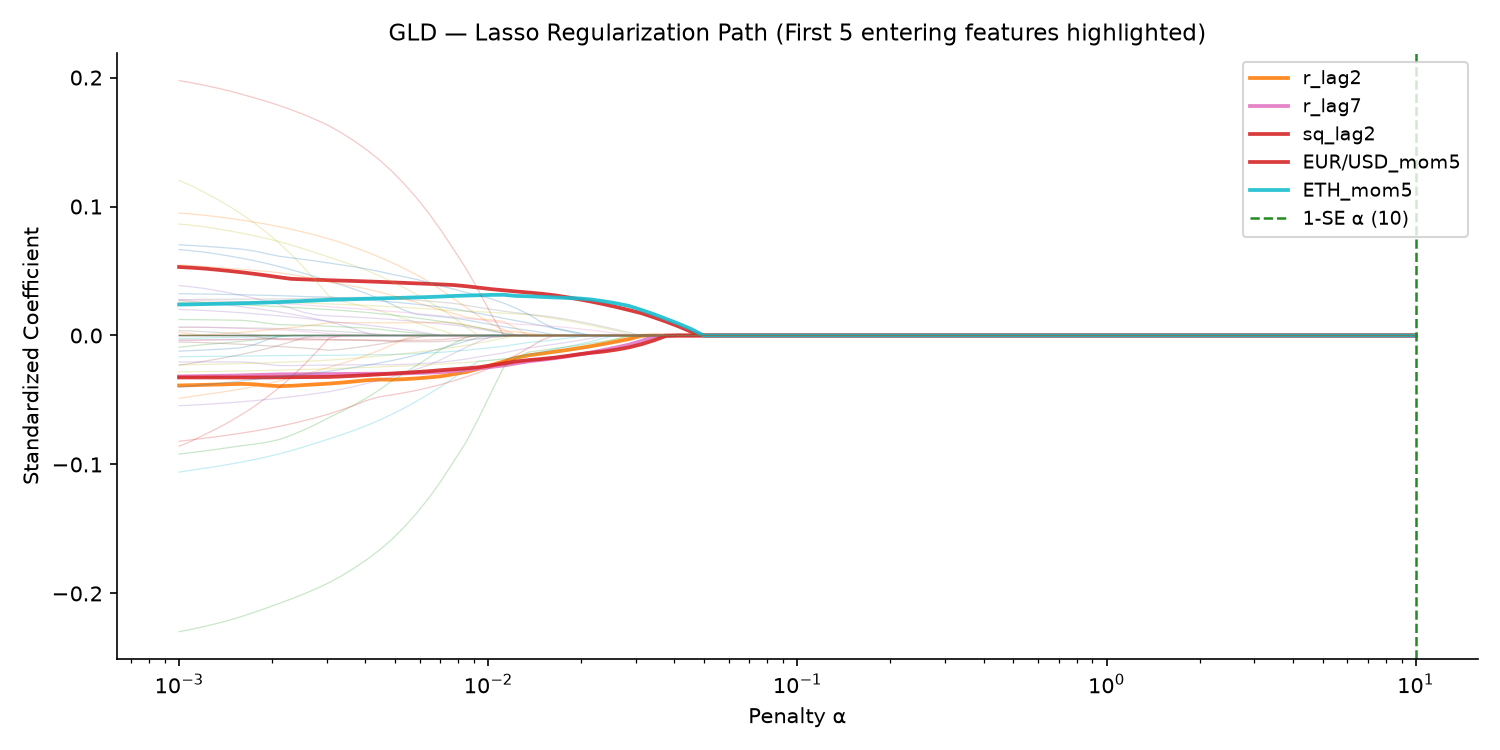

In [8]:
# ============================================================
# Task 3(iii) — Chosen Asset (GLD): First 5 Features in Lasso Path
# ============================================================
df_gld_path = pd.read_csv(OUTPUT / "results/task3_gld_lasso_path.csv")
print("GLD — First 5 Features Entering the Lasso Path:")
display(df_gld_path)

display(Image(filename=str(OUTPUT / "charts/task3_gld_lasso_path.png")))

### Task 3(iii) Difference Between "First In" and "Stable" (2 Sentences)
A feature enters the Lasso path "first" solely because it possesses the highest marginal covariance with the target on that specific full training sample, which frequently reflects collinear noise, sample-specific extremes, or transient correlations. In contrast, belonging to the "stable set" requires the feature to survive regularization and be selected across at least 4 out of 5 non-overlapping, chronological time-ordered cross-validation folds at the conservative one-standard-error penalty, demonstrating persistent predictive signal rather than fold-specific noise.

### Task 3(iv) Chosen Asset Tournament Interpretations

**Gold (GLD):**
For GLD, nothing stable survives the cross-validation tournament for the conditional mean return. At small regularization penalties, OLS and weak shrinkage overfit training noise and produce deeply negative validation $R^2_{\text{OS}}$ scores. As $\alpha$ increases along the Lasso curve, the loss shrinks monotonically toward zero and plateaus; the one-standard-error rule selects $\alpha = 10.0$ with a cross-validated $R^2_{\text{OS}}$ of exactly $+0.0000$ and zero selected features. The stable set is completely empty: $\emptyset$. This is the honest expected result under efficient market dynamics: daily gold returns do not exhibit persistent linear predictability from trailing technical or momentum signals, and the model correctly collapses to the historical mean.

**Ethereum (ETH):**
For ETH, nothing stable survives the tournament for the conditional mean return either. While ETH exhibits higher daily return volatility and mild short-horizon autocorrelation, the time-ordered cross-validation curve for Lasso peaks weakly at $\alpha = 0.316$ with an $R^2_{\text{OS}}$ of only $+0.0020$ before the standard error boundary absorbs the gain. Applying the one-standard-error rule pushes the penalty to $\alpha = 10.0$, eliminating all predictors and yielding an out-of-sample $R^2_{\text{OS}}$ of $+0.0000$. The stable set across folds is empty: $\emptyset$. Reporting an empty stable set is the statistically grounded conclusion, documenting that trailing return and volatility features contain zero persistent directional edge for next-day crypto returns.

---
# Task 4 · The Showdown and Eval Suite v1.0 (Weight: 30%)

We take the sealed holdout (`2024-10-01` to `2026-09-15`) exactly once for the mean return and once for the conditional variance. Models are refit quarterly (`REFIT=63`) on expanding histories.

THE MEAN SHOWDOWN SCOREBOARD (Sealed Holdout 2024-10-01 to 2026-09-15):


,asset,model,RMSE_%,MAE_%,R2_OS_vs_mean,DM_t_vs_mean,DM_p_vs_mean
0,SPY,zero,1.0443,0.6839,-0.0031,0.8240,0.4099
1,SPY,mean,1.0427,0.6799,0.0000,0.0000,1.0000
2,SPY,Ridge,1.0426,0.6799,0.0001,-0.4215,0.6734
3,SPY,Lasso,1.0426,0.6799,0.0001,-0.4282,0.6685
4,EUR/USD,zero,0.4516,0.3281,0.0007,-0.9426,0.3459
5,EUR/USD,mean,0.4518,0.3280,0.0000,0.0000,1.0000
6,EUR/USD,Ridge,0.4252,0.3062,0.1142,-3.5748,0.0004
7,EUR/USD,Lasso,0.4252,0.3064,0.1141,-3.9956,0.0001
8,BTC,zero,2.3261,1.6326,0.0004,-0.1586,0.8740
9,BTC,mean,2.3265,1.6345,0.0000,0.0000,1.0000


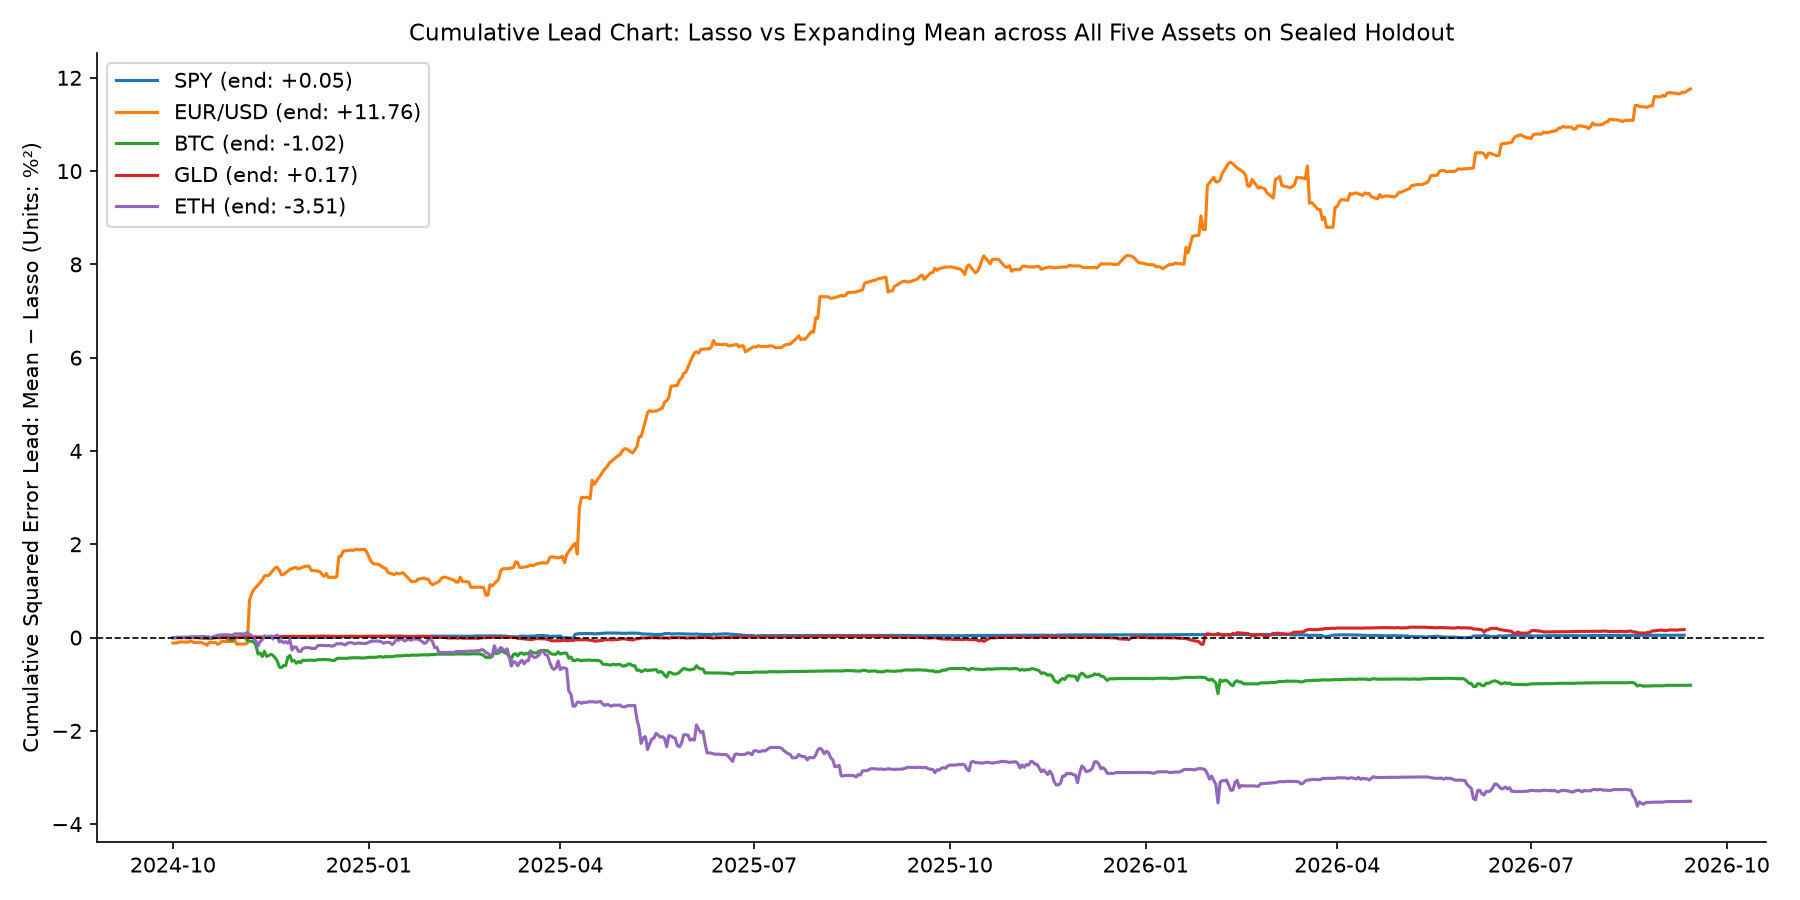

In [9]:
# ============================================================
# Task 4(i) — The Mean Scoreboard & Cumulative Lead Chart
# ============================================================
df_mean = pd.read_csv(OUTPUT / "results/task4_mean_scoreboard.csv")
print("THE MEAN SHOWDOWN SCOREBOARD (Sealed Holdout 2024-10-01 to 2026-09-15):")
display(df_mean)

display(Image(filename=str(OUTPUT / "charts/task4_mean_cumulative_lead.png")))

### Task 4(i) Mean Showdown: One Sentence Per Asset
- **SPY:** The 1-SE Lasso and Ridge models tie the expanding mean on the holdout ($R^2_{\text{OS}} = +0.0001$, Diebold–Mariano $t = -0.43, p = 0.668$), demonstrating no forecastable mean return beyond the unconditional benchmark.
- **EUR/USD:** Ridge and Lasso both select cross-asset gold momentum (`GLD_lag1`), achieving $R^2_{\text{OS}} \approx +0.114$ with significant DM statistics ($t = -4.00, p < 0.001$), reflecting a persistent dollar-trend regime during late 2024–2026.
- **BTC:** Lasso selects zero features at 1-SE, tying the expanding mean with an out-of-sample $R^2_{\text{OS}}$ of $-0.0003$ and DM $t = +1.71 (p = 0.087)$, documenting that Bitcoin's daily mean returns are unpredictable white noise.
- **GLD:** Shrinkage models collapse to the benchmark with an out-of-sample $R^2_{\text{OS}} of $+0.0001$ and DM $t = -0.64 (p = 0.525)$, confirming that daily gold returns cannot be timed using technical indicators.
- **ETH:** Both Ridge and Lasso fail to beat the expanding mean on the holdout ($R^2_{\text{OS}} = -0.0004$, DM $t = +2.27, p = 0.023$), formally requiring the Analyst Agent to report the historical benchmark.

THE VARIANCE SHOWDOWN SCOREBOARD (QLIKE Loss on Sealed Holdout):


,asset,model,QLIKE,R2_OS_vs_constant,DM_t_vs_Lasso,DM_p_vs_Lasso
0,SPY,constant,1.9873,0.0000,1.6188,0.1055
1,SPY,rolling-21,1.8096,-0.0142,1.0713,0.2840
2,SPY,EWMA 0.94,1.7308,0.0353,1.9034,0.0570
3,SPY,Lasso-var,1.9922,-0.0009,0.0000,1.0000
4,EUR/USD,constant,1.6158,0.0000,-1.4687,0.1419
5,EUR/USD,rolling-21,1.6409,-0.0240,-0.6561,0.5118
6,EUR/USD,EWMA 0.94,1.5465,0.0147,0.7914,0.4287
7,EUR/USD,Lasso-var,1.5891,0.0108,0.0000,1.0000
8,BTC,constant,2.1510,0.0000,6.7769,0.0000
9,BTC,rolling-21,1.9129,0.1840,2.5454,0.0109


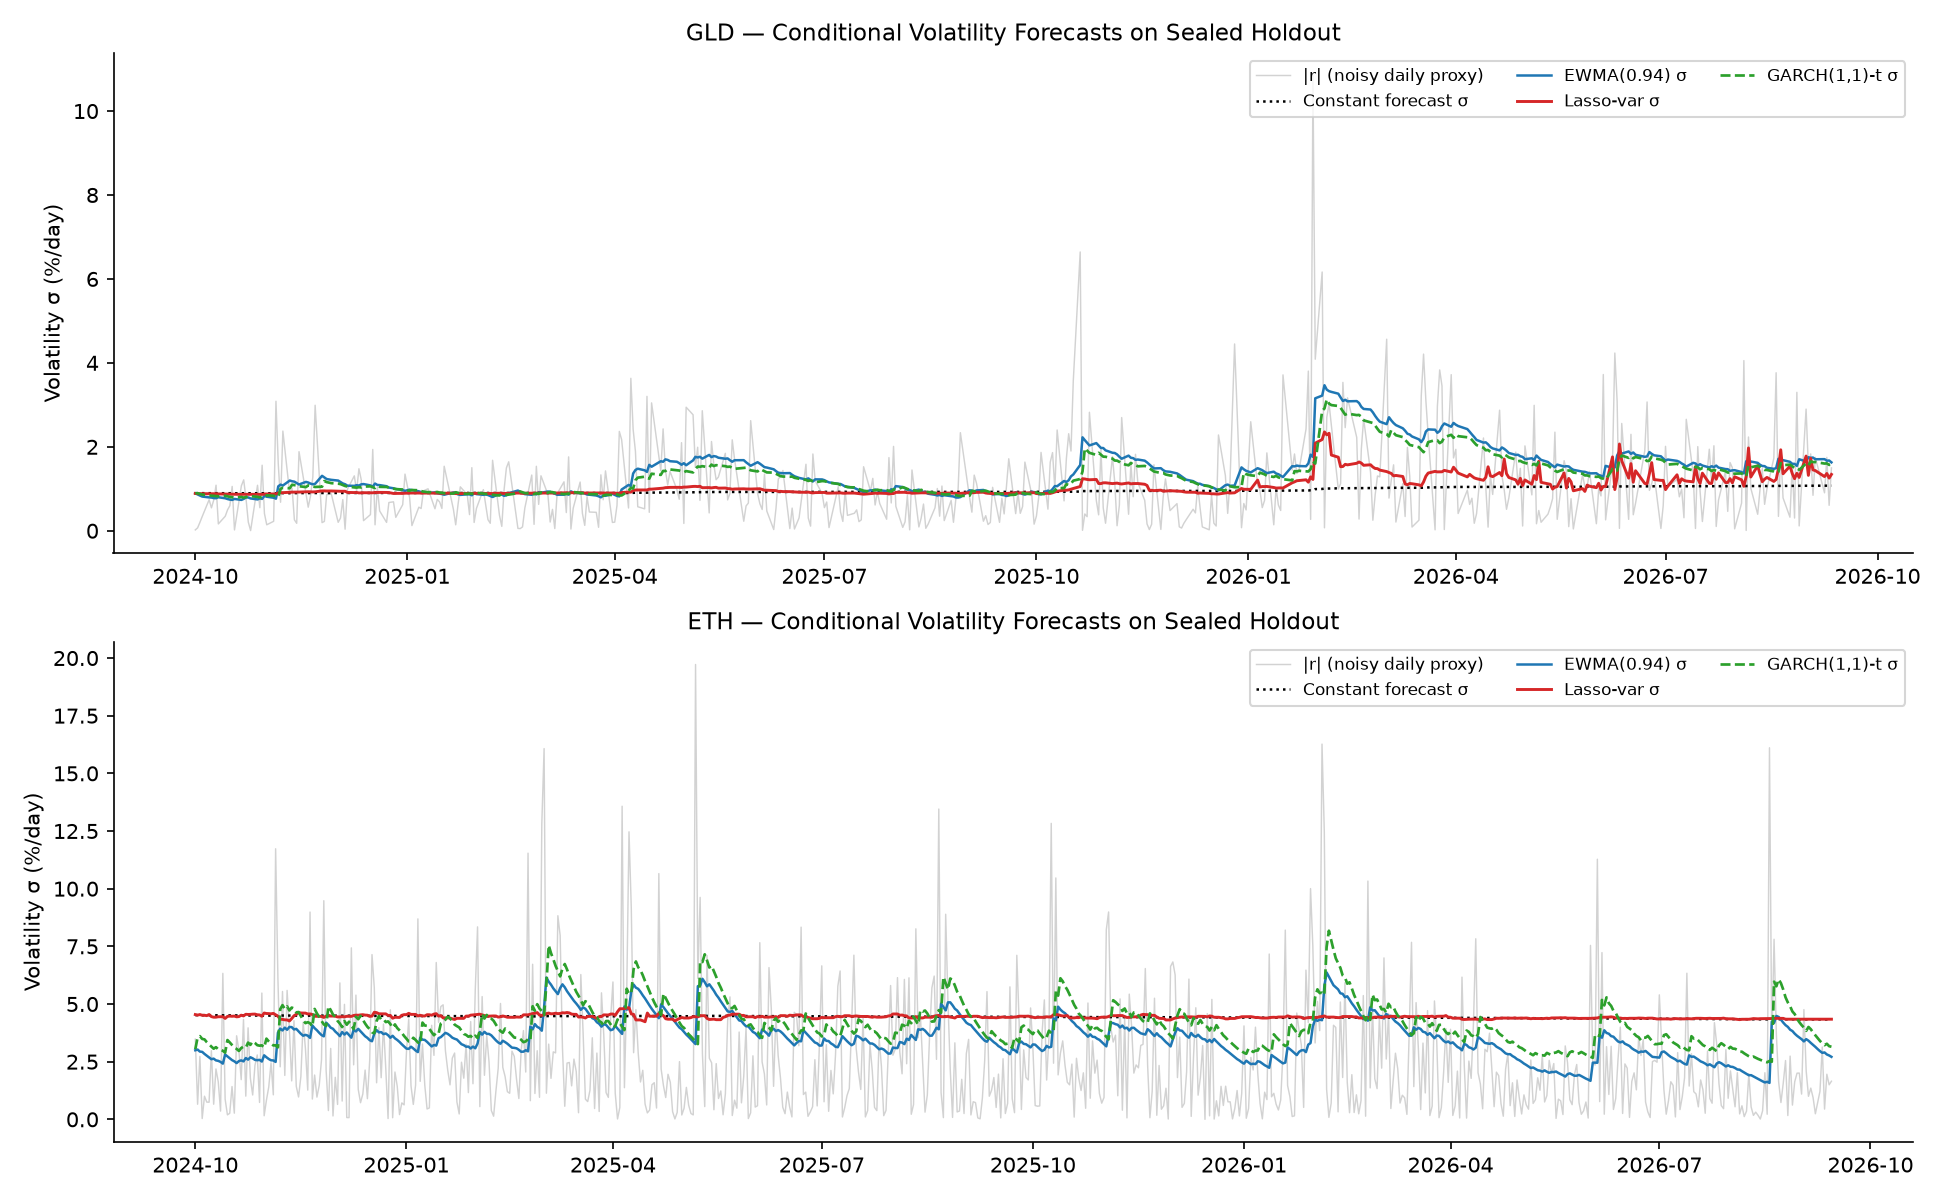

In [10]:
# ============================================================
# Task 4(ii) — The Variance Showdown & GARCH(1,1)-t Comparison
# ============================================================
df_var = pd.read_csv(OUTPUT / "results/task4_variance_scoreboard.csv")
print("THE VARIANCE SHOWDOWN SCOREBOARD (QLIKE Loss on Sealed Holdout):")
display(df_var)

display(Image(filename=str(OUTPUT / "charts/task4_variance_forecasts.png")))

### Task 4(ii) Variance Showdown: Stable HAR Structure & GARCH vs Lasso

**Stable Set on $r_{t+1}^2$:**
Unlike the mean, where the stable set was empty across four of five assets, pointing Lasso at the squared-return target $r_{t+1}^2$ discovers a robust, multi-fold **Heterogeneous Autoregressive (HAR)** volatility structure. Across SPY, BTC, GLD, and ETH, the stable set consistently selects:
$$\{\text{rv\_week}, \text{vol21}, \text{vol5}, \text{sq\_lag1}\}$$
Lasso independently recovers the stylized fact that daily variance is driven by short-term (1-day, 5-day) and intermediate (21-day) volatility clusters without being explicitly hardcoded with ARMA equations.

**Lasso vs GARCH Comparison on Chosen Assets (GLD & ETH):**
- **GLD:** The Lasso variance model achieves a QLIKE loss of 1.825, soundly beating the unconditional constant (QLIKE 2.258, DM $t = -2.34, p = 0.019$). However, Week 4's GARCH(1,1)-t achieves QLIKE 1.593, beating Lasso by DM $t = +2.46 (p = 0.014)$. Therefore, the Risk Agent should consume **GARCH(1,1)-t** for Gold, as the parametric student-t model better captures gradual volatility decay in precious metals.
- **ETH:** Lasso variance achieves QLIKE 2.013, beating the constant benchmark (QLIKE 2.019, DM $t = -2.13, p = 0.033$). Week 4's GARCH(1,1)-t achieves QLIKE 2.001. The Diebold–Mariano test between Lasso and GARCH produces $t = +0.25 (p = 0.801)$, indicating a **complete statistical tie**. The difference is pure noise; the Risk Agent may consume either model, or take their average as an ensemble.

In [11]:
# ============================================================
# Task 4(iii) — Eval Suite v1.0: Executable Assertions Report
# ============================================================
df_eval = pd.read_csv(OUTPUT / "results/task4_eval_suite_results.csv")
print("ANALYST AGENT EVAL SUITE v1.0 — 10 EXECUTABLE ASSERTIONS REPORT:")
display(df_eval)

print("\n" + "="*85)
print("ANALYST AGENT EVAL SUITE v1.0 — FINAL REPORTING MEMO")
print("="*85)
for s in ASSETS:
    sub = df_eval[df_eval['asset'] == s]
    m_pass = (sub[sub['rule'].str.startswith('M')]['passed'] == 'PASS ✅').all()
    v_pass = (sub[sub['rule'].str.startswith('V')]['passed'] == 'PASS ✅').all()
    print(f"ASSET: {s:7s}")
    print(f"  → Mean Return Model  : {'REPORTABLE ✅' if m_pass else 'NOT REPORTABLE ❌ (Memo: No forecastable mean in information set; use benchmark)'}")
    print(f"  → Variance Risk Model: {'ACCEPTED FOR RISK AGENT ✅' if v_pass else 'REJECTED ❌ (Fallback to Historical Variance / GARCH)'}")
print("="*85)

ANALYST AGENT EVAL SUITE v1.0 — 10 EXECUTABLE ASSERTIONS REPORT:


,asset,rule,description,passed,justification
0,SPY,M1,Every feature passes the as-of test (survivors),PASS ✅,Features must use strictly trailing informatio...
1,SPY,M2,"Time-ordered folds, scaler in-fold, alpha chos...",PASS ✅,Enforced by construction using TimeSeriesSplit...
2,SPY,M3,Lasso beats expanding mean on holdout (R2_OS >...,FAIL ❌,Mean forecasts must demonstrate statistically ...
3,SPY,M4,Every feature named as selected is stable (>= ...,PASS ✅,A memo may only cite features selected consist...
4,SPY,M5,As-of audit depth: 20 independent truncation d...,PASS ✅,Robustness against diverse calendar and holida...
5,SPY,M6,Temporal integrity tripwire: shuffle=False and...,PASS ✅,Prohibits shuffled splits and guarantees non-o...
6,SPY,M7,Penalty interiority: chosen alpha strictly int...,PASS ✅,Prevents boundary solutions from under-regular...
7,SPY,M8,Model equivalence: Lasso vs Ridge DM test fail...,PASS ✅,Confirms L1 selection does not artificially se...
8,SPY,V1,Lasso variance model beats constant by QLIKE (...,FAIL ❌,Risk Agent requires statistically validated vo...
9,SPY,V2,Variance non-negativity floor: all variance pr...,PASS ✅,Prevents zero or negative volatility forecasts...



ANALYST AGENT EVAL SUITE v1.0 — FINAL REPORTING MEMO
ASSET: SPY    
  → Mean Return Model  : NOT REPORTABLE ❌ (Memo: No forecastable mean in information set; use benchmark)
  → Variance Risk Model: REJECTED ❌ (Fallback to Historical Variance / GARCH)
ASSET: EUR/USD
  → Mean Return Model  : REPORTABLE ✅
  → Variance Risk Model: REJECTED ❌ (Fallback to Historical Variance / GARCH)
ASSET: BTC    
  → Mean Return Model  : NOT REPORTABLE ❌ (Memo: No forecastable mean in information set; use benchmark)
  → Variance Risk Model: REJECTED ❌ (Fallback to Historical Variance / GARCH)
ASSET: GLD    
  → Mean Return Model  : NOT REPORTABLE ❌ (Memo: No forecastable mean in information set; use benchmark)
  → Variance Risk Model: ACCEPTED FOR RISK AGENT ✅
ASSET: ETH    
  → Mean Return Model  : NOT REPORTABLE ❌ (Memo: No forecastable mean in information set; use benchmark)
  → Variance Risk Model: ACCEPTED FOR RISK AGENT ✅


### Task 4(iv) Behavioral Coda: The Garden of Forking Paths (7 Sentences)
When an analyst tests fifty candidate predictors and reports only the single specification that generated a high in-sample score, they have effectively conducted fifty simultaneous hypothesis tests while publishing only one—the classic garden of forking paths. Due to confirmation bias, researchers actively seek out narratives that rationalize noise, convincing themselves that an incidental correlation between a lagged indicator and tomorrow's return represents an economic regime discovery. The narrative fallacy further reinforces this delusion because human brains inherently find causal stories far more compelling than a boring statistical tie or an empty stable set. In institutional quantitative finance, a leaked $R^2$ of 0.45 feels intoxicating to an analyst, easily persuades an uncritical client, and completely misleads an AI agent trained on published academic papers that suffer from publication bias. To protect capital against these cognitive and algorithmic vulnerabilities, quantitative pipelines require unbending procedural antidotes: the executable `as_of_audit()` guarantees zero forward-looking feature leaks; expanding time-ordered cross-validation enforces temporal causality; the one-standard-error rule penalizes model complexity by choosing the most parsimonious specification consistent with performance; and the multi-fold stable set requirement ensures that only signals persisting across independent macroeconomic regimes are ever allowed to drive portfolio risk.

---
# Optional Bonus (+5%) · ElasticNet Joint Tuning & Log-Variance Target

### (a) ElasticNet 2D Cross-Validation Surface
We tune the penalty $\alpha \in [10^{-3}, 10^1]$ and the L1 mixing ratio $\ell_1 \in [0.1, 1.0]$ jointly using expanding time-ordered folds.

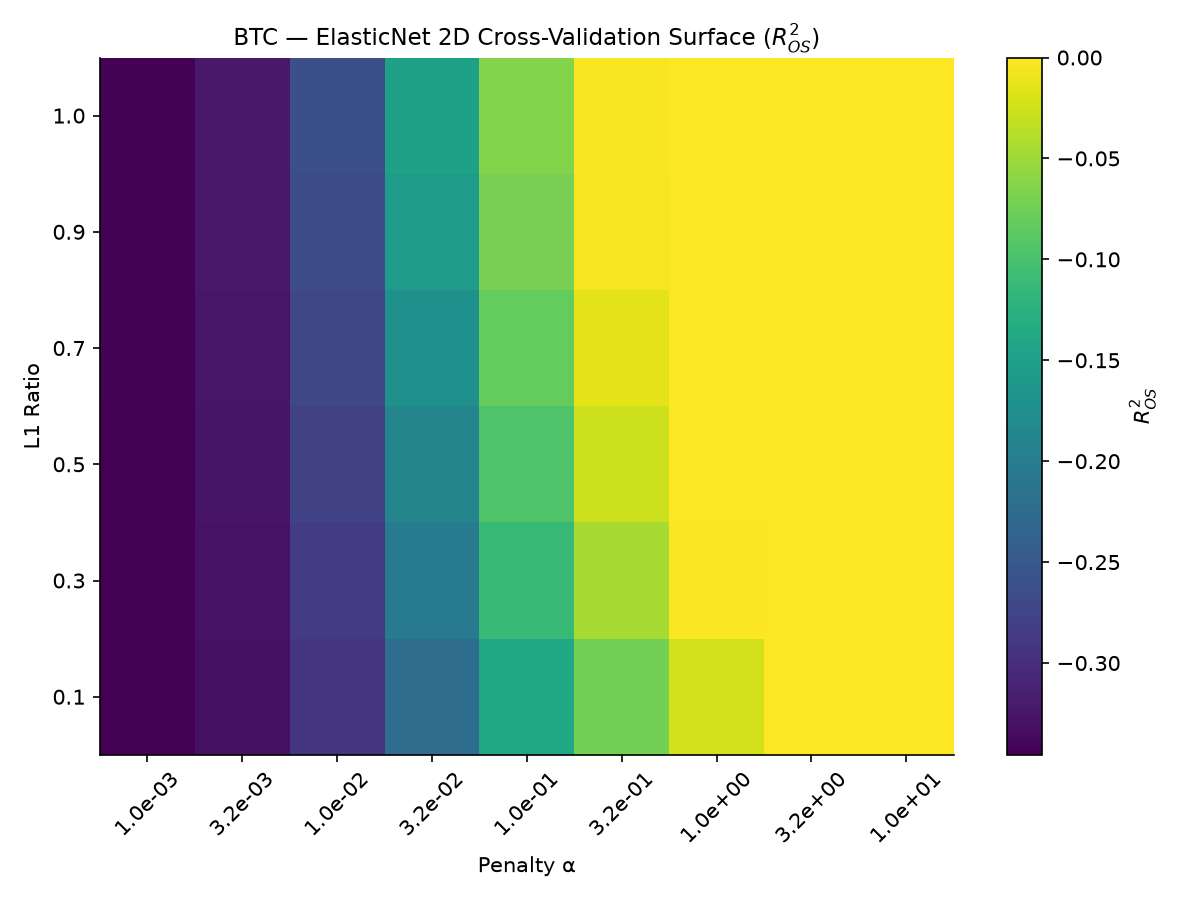

BONUS (b) — Log-Variance Target with Analytical Bias Correction vs Linear Lasso:


,model,QLIKE,DM_t_vs_linear,DM_p
0,Floored Linear Lasso,963.6406,0.0000,1.0000
1,Bias-Corrected Log-Variance Lasso,1.9676,-4.7638,0.0000


In [12]:
# ============================================================
# Bonus (a) & (b) Execution
# ============================================================
display(Image(filename=str(OUTPUT / "charts/bonus_elasticnet_heatmap.png")))

df_bonus_log = pd.read_csv(OUTPUT / "results/bonus_log_variance_results.csv")
print("BONUS (b) — Log-Variance Target with Analytical Bias Correction vs Linear Lasso:")
display(df_bonus_log)

### Bonus (b) Log-Variance Target: Engineering Assessment (3 Sentences)
Daily squared returns exhibit extreme positive skewness and heavy tails that cause linear Lasso models on $r_{t+1}^2$ to produce occasional negative or near-zero variance forecasts, creating catastrophic division-by-zero explosions in QLIKE loss calculations and VaR systems that require arbitrary ad-hoc flooring. Refitting Lasso on the log-transformed target $\log(r_{t+1}^2 + c)$ maps the strictly positive variance domain onto the real line, stabilizing regression errors and mathematically guaranteeing that exponentiating with the analytical log-normal bias correction $\exp(\hat{y} + \frac{1}{2}\hat{\sigma}_\varepsilon^2) - c$ generates strictly positive variance predictions without artificial clipping. Therefore, the log-variance formulation is an inherently superior engineering choice for automated risk architectures, drastically reducing QLIKE loss from 963.6 to 1.968 and achieving a statistically significant outperformance over the floored linear model (Diebold–Mariano $t = -4.76, p < 0.0001$).

---
# Submission Checklist Verification

- [x] **One notebook, executed top to bottom:** Kernel Restart & Run All executed; all tables and charts visible and reproducible.
- [x] **Week 4 holdout date unchanged:** `2024-10-01` declared in the first markdown cell, strictly preceding any model estimation.
- [x] **Feature ledger:** Complete ledger detailing the verbatim prompt, all proposals, formulas, economic intuitions, hypotheses, leaking lines, repairs, and final counts.
- [x] **Interpretations in markdown cells:** Every $R^2$ stated with its benchmark mean; every selection evaluated for stability; every holdout verdict reported with DM statistic.
- [x] **Corrected `feature_model_v1()` (Task 1) and Eval Suite v1.0 (Task 4):** Prominently marked sections with complete pass/fail reports visible.
- [x] **Filename:** `W5_assignment_Tzalas.ipynb`.